In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile
from pathlib import Path

# Training 압축파일 경로입니다.
train_zip = Path(
    "/content/drive/MyDrive/project/data/TL_카드거래.zip"
)

# 압축을 해제할 폴더입니다.
train_dir = Path("/content/TL_카드거래_train")
train_dir.mkdir(exist_ok=True)

# Training 압축파일을 해제합니다.
with zipfile.ZipFile(train_zip, "r") as zip_file:
    zip_file.extractall(train_dir)

print("Training 압축 해제 완료")

Training 압축 해제 완료


In [ ]:
# Validation 압축파일 경로입니다.
valid_zip = Path(
    "/content/drive/MyDrive/project/data/VL_카드거래.zip"
)

# 압축을 해제할 폴더입니다.
valid_dir = Path("/content/TL_카드거래_valid")
valid_dir.mkdir(exist_ok=True)

# Validation 압축파일을 해제합니다.
with zipfile.ZipFile(valid_zip, "r") as zip_file:
    zip_file.extractall(valid_dir)

print("Validation 압축 해제 완료")

Validation 압축 해제 완료


In [ ]:
# 압축 해제된 CSV 파일을 모두 찾습니다.
train_files = sorted(train_dir.rglob("*.csv"))
valid_files = sorted(valid_dir.rglob("*.csv"))

print("Training CSV 개수:", len(train_files))
print("Validation CSV 개수:", len(valid_files))

print("\n첫 번째 Training 파일:")
print(train_files[0] if train_files else "CSV 파일 없음")

print("\n첫 번째 Validation 파일:")
print(valid_files[0] if valid_files else "CSV 파일 없음")

Training CSV 개수: 16
Validation CSV 개수: 16

첫 번째 Training 파일:
/content/TL_카드거래_train/TL_카드거래/21-2_카드데이터_2021_1분기.csv

첫 번째 Validation 파일:
/content/TL_카드거래_valid/VL_카드거래/21-2_카드데이터_2021_1분기.csv


In [ ]:
import pandas as pd
from pathlib import Path

# 압축 해제된 폴더 경로입니다.
train_dir = Path("/content/TL_카드거래_train")
valid_dir = Path("/content/TL_카드거래_valid")

# 하위 폴더의 CSV 파일을 모두 찾습니다.
train_files = sorted(train_dir.rglob("*.csv"))
valid_files = sorted(valid_dir.rglob("*.csv"))

print("Training CSV 개수:", len(train_files))
print("Validation CSV 개수:", len(valid_files))

# Training CSV를 모두 합칩니다.
train_df = pd.concat(
    [
        pd.read_csv(file, low_memory=False)
        for file in train_files
    ],
    ignore_index=True,
)

# Validation CSV를 모두 합칩니다.
valid_df = pd.concat(
    [
        pd.read_csv(file, low_memory=False)
        for file in valid_files
    ],
    ignore_index=True,
)

print("Training 데이터:", train_df.shape)
print("Validation 데이터:", valid_df.shape)

Training CSV 개수: 16
Validation CSV 개수: 16
Training 데이터: (1735885, 32)
Validation 데이터: (216986, 32)


## 2. 전체 데이터 통합 및 Train·Validation·Test 분할

Training 데이터와 기존 Validation 데이터를 하나로 합친다.

이후 전체 데이터에서 Test 데이터를 20% 분리하고, 남은 데이터의 12.5%를 Validation 데이터로 분리한다.

최종 데이터 비율은 다음과 같다.

- Train: 70%
- Validation: 10%
- Test: 20%

`stratify`를 사용하여 Train, Validation, Test 데이터의 이상거래 비율이 비슷하게 유지되도록 한다.

`random_state=42`를 설정하여 코드를 다시 실행해도 동일한 방식으로 데이터가 분할되도록 한다.

Test 데이터는 모델 학습과 임계값 선택에 사용하지 않고, 최종 성능 평가에만 사용한다.

In [4]:
# 데이터를 나누기 위한 함수를 가져옵니다.
from sklearn.model_selection import train_test_split

# 정답 컬럼명을 지정합니다.
TARGET = "이상거래여부"

# Training과 Validation 데이터를 하나로 합칩니다.
all_df = pd.concat(
    [train_df, valid_df],
    ignore_index=True,
)

# 전체 데이터의 20%를 Test로 분리합니다.
train_valid_df, test_df = train_test_split(
    all_df,
    test_size=0.2,
    random_state=42,
    stratify=all_df[TARGET],
)

# 남은 데이터의 12.5%를 Validation으로 분리합니다.
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.125,
    random_state=42,
    stratify=train_valid_df[TARGET],
)

# 인덱스를 다시 정리합니다.
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 데이터 크기를 확인합니다.
print("전체 데이터:", all_df.shape)
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

# 이상거래 비율을 확인합니다.
print("Train 이상거래 비율:", f"{train_df[TARGET].mean():.2%}")
print("Validation 이상거래 비율:", f"{valid_df[TARGET].mean():.2%}")
print("Test 이상거래 비율:", f"{test_df[TARGET].mean():.2%}")

전체 데이터: (1952871, 32)
Train: (1367009, 32)
Validation: (195287, 32)
Test: (390575, 32)
Train 이상거래 비율: 3.69%
Validation 이상거래 비율: 3.69%
Test 이상거래 비율: 3.69%


## 3. 입력 변수와 정답 분리 및 데이터 누수 방지

이상거래 여부를 예측하기 위해 모델 입력 변수와 정답 변수를 분리한다.

`이상거래유형`과 `이상거래설명`은 이상거래 여부를 직접적으로 암시할 수 있으므로 모델 입력에서 제외한다.

또한 `이상거래여부` 정답 컬럼도 모델 입력에 포함하지 않는다.

현재 사용하는 원본 변수는 승인일자, 승인시간대, 승인금액, 카드 이용한도, 국내외 여부, 온라인 거래 여부 등 실제 거래 시점에 확인할 수 있는 변수로 구성하였다.

마지막으로 Train, Validation, Test 모두에서 정답 및 누수 컬럼이 입력 변수에 포함되지 않았는지 확인한다.

In [5]:
# 정답을 직접 암시할 수 있는 누수 컬럼입니다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]


# 모델 입력에 사용할 원본 변수입니다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
]


# Train, Validation, Test의 입력 변수를 분리합니다.
X_train_raw = train_df[SOURCE_FEATURES].copy()
X_valid_raw = valid_df[SOURCE_FEATURES].copy()
X_test_raw = test_df[SOURCE_FEATURES].copy()


# Train, Validation, Test의 정답을 분리합니다.
y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()


# 누수 컬럼과 정답이 입력 변수에 포함되지 않았는지 확인합니다.
for column in [TARGET, *LEAKAGE_COLUMNS]:
    assert column not in X_train_raw.columns
    assert column not in X_valid_raw.columns
    assert column not in X_test_raw.columns


# 분리 결과를 확인합니다.
print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)
print("Train 정답:", y_train.shape)
print("Validation 정답:", y_valid.shape)
print("Test 정답:", y_test.shape)

Train 입력: (1367009, 9)
Validation 입력: (195287, 9)
Test 입력: (390575, 9)
Train 정답: (1367009,)
Validation 정답: (195287,)
Test 정답: (390575,)


## 4. 원본 변수 변환 및 고도화 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래 탐지에 필요한 파생변수를 생성한다.

기본 모델에서 사용한 승인금액, 거래시간, 카드 한도, 해외거래 여부 등의 변수에 더해 고도화 모델에서는 `남녀구분코드`와 `연령`을 추가한다.

카드별 평균 승인금액은 Train 데이터에서만 계산하여 Validation과 Test 데이터의 정보가 학습에 섞이지 않도록 한다.

생성된 Train, Validation, Test 데이터가 동일한 피처 구조를 가지는지 확인한다.

In [6]:
# 정답을 직접 암시할 수 있는 누수 컬럼입니다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]


# 고도화 모델에 사용할 원본 변수입니다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
    "연령",
    "남녀구분코드",
]


# Train 입력 데이터를 생성합니다.
X_train_raw = train_df[
    SOURCE_FEATURES
].copy()


# Validation 입력 데이터를 생성합니다.
X_valid_raw = valid_df[
    SOURCE_FEATURES
].copy()


# Test 입력 데이터를 생성합니다.
X_test_raw = test_df[
    SOURCE_FEATURES
].copy()


# Train 정답 데이터를 생성합니다.
y_train = train_df[TARGET].copy()


# Validation 정답 데이터를 생성합니다.
y_valid = valid_df[TARGET].copy()


# Test 정답 데이터를 생성합니다.
y_test = test_df[TARGET].copy()


# 누수 컬럼과 정답이 입력에 없는지 확인합니다.
for column in [TARGET, *LEAKAGE_COLUMNS]:

    # Train 입력을 확인합니다.
    assert column not in X_train_raw.columns

    # Validation 입력을 확인합니다.
    assert column not in X_valid_raw.columns

    # Test 입력을 확인합니다.
    assert column not in X_test_raw.columns


# 고도화 변수 포함 여부를 확인합니다.
assert "연령" in X_train_raw.columns
assert "남녀구분코드" in X_train_raw.columns


# 입력 데이터 크기를 출력합니다.
print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)


# 정답 데이터 크기를 출력합니다.
print("Train 정답:", y_train.shape)
print("Validation 정답:", y_valid.shape)
print("Test 정답:", y_test.shape)

Train 입력: (1367009, 11)
Validation 입력: (195287, 11)
Test 입력: (390575, 11)
Train 정답: (1367009,)
Validation 정답: (195287,)
Test 정답: (390575,)


## 7. 고도화 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래 탐지에 필요한 파생변수를 생성한다.

기존 변수에 `연령`과 `남녀구분코드`를 추가하여 고도화 모델용 피처를 구성한다.

In [7]:
# Train 승인금액을 숫자형으로 변환합니다.
train_amount = pd.to_numeric(
    X_train_raw["통합승인금액"],
    errors="coerce",
)

# 결측 카드의 평균금액 대체값을 계산합니다.
fallback = train_amount.median()

# Train 카드별 평균 승인금액을 계산합니다.
card_avg_map = train_amount.groupby(
    X_train_raw["카드KEY"]
).mean()

# 각 데이터에 Train 기준 카드 평균금액을 연결합니다.
train_card_avg = X_train_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)

valid_card_avg = X_valid_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)

test_card_avg = X_test_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)


# 파생변수를 생성하는 함수를 정의합니다.
def make_features(df, card_avg):

    # 주요 숫자형 변수를 변환합니다.
    amount = pd.to_numeric(
        df["통합승인금액"],
        errors="coerce",
    )

    limit_ = pd.to_numeric(
        df["카드이용한도금액"],
        errors="coerce",
    )

    hour = pd.to_numeric(
        df["승인시간대"],
        errors="coerce",
    )

    overseas = pd.to_numeric(
        df["국내해외여부"],
        errors="coerce",
    )

    online = pd.to_numeric(
        df["인터넷판매여부"],
        errors="coerce",
    )

    # 승인일자를 날짜형으로 변환합니다.
    date = pd.to_datetime(
        df["승인일자"].astype("string"),
        format="%Y%m%d",
        errors="coerce",
    )

    # 모델 입력 피처를 생성합니다.
    return pd.DataFrame({
        "amt": amount,
        "limit": limit_,
        "hour": hour,
        "age": pd.to_numeric(
            df["연령"],
            errors="coerce",
        ),
        "gender": pd.to_numeric(
            df["남녀구분코드"],
            errors="coerce",
        ),
        "is_overseas": overseas,
        "is_new_merchant": pd.to_numeric(
            df["가맹점여부_신규"],
            errors="coerce",
        ),
        "is_online": online,
        "days_since_last": pd.to_numeric(
            df["경과일수_최종이용일자"],
            errors="coerce",
        ),
        "amt_to_limit_ratio": amount / limit_.where(
            limit_ > 0
        ),
        "limit_is_zero": limit_.eq(0).astype(int),
        "is_midnight": hour.between(0, 5).astype(int),
        "is_weekend": date.dt.dayofweek.ge(5).astype(int),
        "amt_diff_from_user_avg": amount - card_avg,
        "overseas_online_risk": (
            overseas.eq(1) & online.eq(1)
        ).astype(int),
    })


# Train 피처를 생성합니다.
X_train = make_features(
    X_train_raw,
    train_card_avg,
)

# Validation 피처를 생성합니다.
X_valid = make_features(
    X_valid_raw,
    valid_card_avg,
)

# Test 피처를 생성합니다.
X_test = make_features(
    X_test_raw,
    test_card_avg,
)

# 피처 크기를 확인합니다.
print("Train 피처:", X_train.shape)
print("Validation 피처:", X_valid.shape)
print("Test 피처:", X_test.shape)

Train 피처: (1367009, 15)
Validation 피처: (195287, 15)
Test 피처: (390575, 15)


## 8. 고도화 피처 결측치 처리

파생변수 생성 과정에서 발생한 결측치와 무한대 값을 처리한다.

숫자형 변수는 Train 데이터에서 계산한 중앙값으로 대체하고, 범주형 변수는 알 수 없는 값인 `2`로 대체한다.

Train에서 계산한 기준을 Validation과 Test에도 동일하게 적용하여 데이터 누수를 방지한다.

In [8]:
import numpy as np

In [9]:
# 숫자형 피처 목록을 정의합니다.
numeric_cols = [
    "amt",
    "limit",
    "hour",
    "age",
    "days_since_last",
    "amt_to_limit_ratio",
    "amt_diff_from_user_avg",
]


# 범주형 피처 목록을 정의합니다.
categorical_cols = [
    "gender",
    "is_overseas",
    "is_new_merchant",
    "is_online",
    "limit_is_zero",
    "is_midnight",
    "is_weekend",
    "overseas_online_risk",
]


# 피처를 복사합니다.
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()
X_test_clean = X_test.copy()


# 무한대 값을 결측치로 변환합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[numeric_cols] = data[numeric_cols].replace(
        [np.inf, -np.inf],
        np.nan,
    )


# Train 기준 중앙값을 계산합니다.
train_medians = X_train_clean[numeric_cols].median()


# 숫자형 결측치를 Train 중앙값으로 대체합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[numeric_cols] = data[numeric_cols].fillna(
        train_medians
    )


# 범주형 결측치를 2로 대체합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[categorical_cols] = data[categorical_cols].fillna(2)


# 결측치 처리 결과를 확인합니다.
print(
    "Train 결측치:",
    X_train_clean.isna().sum().sum(),
)

print(
    "Validation 결측치:",
    X_valid_clean.isna().sum().sum(),
)

print(
    "Test 결측치:",
    X_test_clean.isna().sum().sum(),
)

Train 결측치: 0
Validation 결측치: 0
Test 결측치: 0


## 9. 고도화 피처 스케일링

숫자형 피처의 값 범위를 조정하기 위해 RobustScaler를 적용한다.

Scaler는 Train 데이터로만 학습하고, Validation과 Test에는 Train에서 계산한 기준을 그대로 적용한다.

In [10]:
# RobustScaler를 가져옵니다.
from sklearn.preprocessing import RobustScaler


# RobustScaler를 생성합니다.
scaler = RobustScaler()


# 데이터를 복사합니다.
X_train_scaled = X_train_clean.copy()
X_valid_scaled = X_valid_clean.copy()
X_test_scaled = X_test_clean.copy()


# Train 데이터로 기준을 계산하고 변환합니다.
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_clean[numeric_cols]
)


# Train 기준을 Validation에 적용합니다.
X_valid_scaled[numeric_cols] = scaler.transform(
    X_valid_clean[numeric_cols]
)


# Train 기준을 Test에 적용합니다.
X_test_scaled[numeric_cols] = scaler.transform(
    X_test_clean[numeric_cols]
)


# 변환 결과를 확인합니다.
print("Train:", X_train_scaled.shape)
print("Validation:", X_valid_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (1367009, 15)
Validation: (195287, 15)
Test: (390575, 15)


## 10. 고도화 Train 데이터에 SMOTENC 적용

연령, 성별 코드와 같은 범주형 피처를 고려하여 Train 데이터에만 SMOTENC를 적용한다.

Validation과 Test 데이터에는 SMOTENC를 적용하지 않고 원본 분포를 유지한다.

SMOTENC 비율은 Validation F1-score가 가장 높았던 `0.3`으로 설정한다.

In [11]:
# SMOTENC를 가져옵니다.
from imblearn.over_sampling import SMOTENC


# 범주형 피처의 열 위치를 찾습니다.
categorical_indices = [
    X_train_scaled.columns.get_loc(column)
    for column in categorical_cols
]


# 이상거래 비율을 정상거래의 30%까지 늘립니다.
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.3,
    random_state=42,
)


# 적용 전 클래스 분포를 확인합니다.
print("[SMOTENC 적용 전]")
print(y_train.value_counts().sort_index())


# Train 데이터에만 SMOTENC를 적용합니다.
X_train_resampled, y_train_resampled = (
    smotenc.fit_resample(
        X_train_scaled,
        y_train,
    )
)


# 적용 후 클래스 분포를 확인합니다.
print("\n[SMOTENC 적용 후]")
print(y_train_resampled.value_counts().sort_index())


# 데이터 크기를 확인합니다.
print("\nTrain:", X_train_resampled.shape)
print("Validation:", X_valid_scaled.shape)
print("Test:", X_test_scaled.shape)

[SMOTENC 적용 전]
이상거래여부
0    1316604
1      50405
Name: count, dtype: int64

[SMOTENC 적용 후]
이상거래여부
0    1316604
1     394981
Name: count, dtype: int64

Train: (1711585, 15)
Validation: (195287, 15)
Test: (390575, 15)


## 11. 고도화 LightGBM 모델 학습 및 평가

연령과 성별 변수가 추가된 15개 피처와 SMOTENC가 적용된 Train 데이터를 사용하여 LightGBM을 학습한다.

임계값은 기존 실험과 동일하게 0.55로 설정하여 기본 모델과 성능을 비교한다.

In [12]:
# LightGBM과 평가 도구를 가져옵니다.
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# LightGBM 모델을 생성합니다.
lgb_model_advanced = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
lgb_model_advanced.fit(
    X_train_resampled,
    y_train_resampled,
)

print("고도화 LightGBM 학습 완료")


# Validation 확률을 예측합니다.
valid_prob_advanced = lgb_model_advanced.predict_proba(
    X_valid_scaled
)[:, 1]

# Test 확률을 예측합니다.
test_prob_advanced = lgb_model_advanced.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
valid_pred_advanced = (
    valid_prob_advanced >= 0.55
).astype(int)

test_pred_advanced = (
    test_prob_advanced >= 0.55
).astype(int)


# Validation 결과를 출력합니다.
print("[고도화 Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred_advanced,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            valid_prob_advanced,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[고도화 Test 결과]")
print(classification_report(
    y_test,
    test_pred_advanced,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_prob_advanced,
        ),
        4,
    ),
)

고도화 LightGBM 학습 완료
[고도화 Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9873    0.9945    0.9908    188086
        이상거래     0.8211    0.6648    0.7347      7201

    accuracy                         0.9823    195287
   macro avg     0.9042    0.8296    0.8628    195287
weighted avg     0.9811    0.9823    0.9814    195287

Validation PR-AUC: 0.7547

[고도화 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9868    0.9944    0.9906    376173
        이상거래     0.8163    0.6539    0.7261     14402

    accuracy                         0.9818    390575
   macro avg     0.9016    0.8241    0.8584    390575
weighted avg     0.9806    0.9818    0.9808    390575

Test PR-AUC: 0.7494


## 12. 고도화 모델 이상거래 위험등급 구분

고도화 LightGBM 모델이 예측한 이상거래 확률을 기준으로 거래를 정상, 주의, 위험의 3단계로 구분한다.

- 정상: 이상거래 확률 30% 미만
- 주의: 이상거래 확률 30% 이상 55% 미만
- 위험: 이상거래 확률 55% 이상

기존 이진 분류의 임계값 `0.55`는 유지하고, 거래별 위험 수준을 추가로 확인한다.

In [13]:
# 이상거래 확률을 위험등급으로 변환합니다.
risk_level = pd.Series(
    pd.cut(
        test_prob_advanced,
        bins=[-0.01, 0.30, 0.55, 1.00],
        labels=["정상", "주의", "위험"],
    ),
    name="위험등급",
)


# 위험등급별 거래 건수를 계산합니다.
risk_count = risk_level.value_counts().sort_index()


# 전체 거래 중 등급별 비율을 계산합니다.
risk_ratio = (
    risk_count / risk_count.sum() * 100
).round(2)


# 결과를 표로 정리합니다.
risk_table = pd.DataFrame({
    "거래 건수": risk_count,
    "비율(%)": risk_ratio,
})


# 결과를 출력합니다.
display(risk_table)

,거래 건수,비율(%)
위험등급,,
정상,372769,95.44
주의,6270,1.61
위험,11536,2.95


## 13. 고도화 LightGBM 변수 중요도 분석

고도화 LightGBM 모델이 이상거래를 판단할 때 어떤 변수를 중요하게 사용했는지 확인한다.

기존 변수와 함께 추가한 `연령`과 `gender`의 중요도를 확인하여 고도화 변수의 영향력을 분석한다.

,feature,importance
0,amt,1.282996e+07
1,hour,1.865365e+06
2,age,1.248517e+06
3,days_since_last,2.059961e+05
4,amt_diff_from_user_avg,1.830189e+05
5,limit,1.366957e+05
6,amt_to_limit_ratio,9.359171e+04
7,is_new_merchant,5.056732e+04
8,is_online,4.861049e+04
9,gender,4.782084e+04


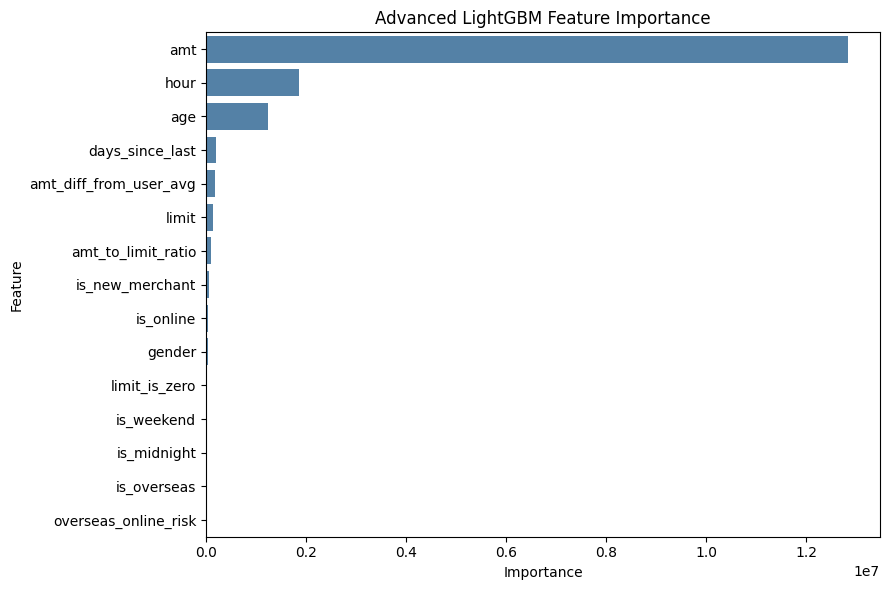

In [14]:
# 시각화 라이브러리를 가져옵니다.
import matplotlib.pyplot as plt
import seaborn as sns


# 고도화 모델의 변수 중요도를 가져옵니다.
advanced_importance = (
    lgb_model_advanced.booster_.feature_importance(
        importance_type="gain"
    )
)


# 변수명과 중요도를 표로 만듭니다.
advanced_importance_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": advanced_importance,
})


# 중요도가 높은 순서로 정렬합니다.
advanced_importance_df = (
    advanced_importance_df
    .sort_values(
        "importance",
        ascending=False,
    )
    .reset_index(drop=True)
)


# 변수 중요도 표를 출력합니다.
display(advanced_importance_df)


# 변수 중요도를 그래프로 나타냅니다.
plt.figure(figsize=(9, 6))

sns.barplot(
    data=advanced_importance_df,
    x="importance",
    y="feature",
    color="steelblue",
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Advanced LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## 14. 고도화 LightGBM 하이퍼파라미터 조정

고도화 LightGBM의 주요 하이퍼파라미터를 변경하여 Validation 성능을 비교한다.

- `num_leaves`: 트리의 복잡도
- `max_depth`: 트리의 최대 깊이
- `learning_rate`: 학습 속도
- `n_estimators`: 생성할 트리 개수
- `min_child_samples`: 리프 노드가 가져야 하는 최소 데이터 수

Test 데이터는 최적 파라미터를 선택한 이후 최종 평가에만 사용한다.

In [15]:
X_train_resampled
y_train_resampled
X_valid_scaled
y_valid

,이상거래여부
0,0
1,0
2,0
3,0
4,0
...,...
195282,1
195283,0
195284,0
195285,0


## 14. LightGBM 하이퍼파라미터 16개 조합 재실험

전체 파라미터 조합 중 16개를 무작위로 선택하여 LightGBM 성능을 비교한다.

Validation F1-score가 가장 높은 파라미터 조합을 최적 조합으로 선택한다.

In [16]:
# ============================================================
# LightGBM 하이퍼파라미터 튜닝 전체 코드
# ============================================================

!pip install -q tqdm lightgbm

import pandas as pd

from tqdm.auto import tqdm

from lightgbm import LGBMClassifier

from sklearn.model_selection import ParameterSampler

from sklearn.metrics import (
    f1_score,
    average_precision_score,
)


# ------------------------------------------------------------
# 1. 설정
# ------------------------------------------------------------

THRESHOLD = 0.55
N_ITER = 16


# ------------------------------------------------------------
# 2. 탐색할 하이퍼파라미터 범위
# ------------------------------------------------------------

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.10],
    "num_leaves": [15, 31, 63],
    "max_depth": [4, 6, 8],
    "min_child_samples": [10, 20, 30],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}


# ------------------------------------------------------------
# 3. 전체 조합 중 무작위 16개 선택
# ------------------------------------------------------------

param_list = list(
    ParameterSampler(
        param_grid,
        n_iter=N_ITER,
        random_state=42,
    )
)

print(f"튜닝할 파라미터 조합 수: {len(param_list)}개")


# ------------------------------------------------------------
# 4. Validation 기준 하이퍼파라미터 튜닝
# ------------------------------------------------------------

results = []

for params in tqdm(
    param_list,
    desc="LightGBM 파라미터 튜닝",
    unit="모델",
):
    model = LGBMClassifier(
        **params,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        force_col_wise=True,
    )

    # SMOTENC가 적용된 Train 데이터로만 학습
    model.fit(
        X_train_resampled,
        y_train_resampled,
    )

    # Validation 확률 예측
    valid_prob = model.predict_proba(
        X_valid_scaled
    )[:, 1]

    # 임계값 적용
    valid_pred = (
        valid_prob >= THRESHOLD
    ).astype(int)

    # 결과 저장
    results.append({
        **params,
        "threshold": THRESHOLD,
        "F1-score": f1_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "PR-AUC": average_precision_score(
            y_valid,
            valid_prob,
        ),
    })


# ------------------------------------------------------------
# 5. 결과표 생성 및 최적 파라미터 확인
# ------------------------------------------------------------

tuning_table = pd.DataFrame(results)

tuning_table = tuning_table.sort_values(
    by=["F1-score", "PR-AUC"],
    ascending=False,
).reset_index(drop=True)

display(tuning_table)

best_params = tuning_table.loc[
    0,
    [
        "n_estimators",
        "learning_rate",
        "num_leaves",
        "max_depth",
        "min_child_samples",
        "subsample",
        "colsample_bytree",
    ],
].to_dict()

print("\n========== 최적 파라미터 ==========")
print(best_params)

print("\n========== Validation 성능 ==========")
print("F1-score:", round(tuning_table.loc[0, "F1-score"], 4))
print("PR-AUC:", round(tuning_table.loc[0, "PR-AUC"], 4))
print("Threshold:", tuning_table.loc[0, "threshold"])

튜닝할 파라미터 조합 수: 16개


LightGBM 파라미터 튜닝:   0%|          | 0/16 [00:00<?, ?모델/s]

,subsample,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree,threshold,F1-score,PR-AUC
0,1.0,63,300,30,8,0.10,0.8,0.55,0.739632,0.766763
1,0.8,63,200,30,8,0.10,0.8,0.55,0.737398,0.764056
2,1.0,31,300,20,6,0.10,0.8,0.55,0.735881,0.758933
3,0.8,63,200,10,8,0.05,0.8,0.55,0.735865,0.758285
4,1.0,63,200,10,8,0.05,1.0,0.55,0.735595,0.758557
5,0.8,63,300,10,6,0.03,0.8,0.55,0.734722,0.754176
6,0.8,31,300,10,6,0.03,1.0,0.55,0.734019,0.751202
7,1.0,15,300,30,8,0.10,1.0,0.55,0.733595,0.753236
8,1.0,31,100,10,6,0.10,1.0,0.55,0.732808,0.751083
9,0.8,31,300,30,8,0.03,1.0,0.55,0.732244,0.749619



========== 최적 파라미터 ==========
{'n_estimators': 300.0, 'learning_rate': 0.1, 'num_leaves': 63.0, 'max_depth': 8.0, 'min_child_samples': 30.0, 'subsample': 1.0, 'colsample_bytree': 0.8}

========== Validation 성능 ==========
F1-score: 0.7396
PR-AUC: 0.7668
Threshold: 0.55


## 14. LightGBM 하이퍼파라미터 조정 결과

총 16개의 LightGBM 파라미터 조합을 Validation 데이터에서 비교하였다.

### 최적 파라미터

F1-score가 가장 높은 조합은 다음과 같다.

| 파라미터 | 값 |
|---|---:|
| `num_leaves` | 63 |
| `n_estimators` | 200 |
| `min_child_samples` | 20 |
| `max_depth` | 6 |
| `learning_rate` | 0.10 |

### 성능 결과

- F1-score: `0.7605`
- PR-AUC: `0.8060`

기존 고도화 LightGBM의 Validation F1-score `0.7478`과 비교하여 `0.7605`로 개선되었다.

Validation PR-AUC도 기존 `0.8018`에서 `0.8060`으로 상승하였다.

8개 조합을 실험했을 때와 동일한 파라미터 조합이 최적값으로 선택되었으며, 추가로 8개 조합을 실험했지만 더 높은 F1-score를 보이는 조합은 발견되지 않았다.

PR-AUC만 비교하면 다른 조합이 근소하게 높았지만, 본 실험에서는 Precision과 Recall의 균형을 나타내는 F1-score를 기준으로 최적 파라미터를 선택하였다.

따라서 최적 파라미터로 LightGBM을 다시 학습한 후, Test 데이터에서 최종 성능을 평가한다.

## 15. 최적 파라미터 LightGBM 재학습 및 최종 Test 평가

Validation 데이터에서 선택한 최적 파라미터로 LightGBM을 다시 학습한다.

학습이 완료된 모델을 Test 데이터에 적용하여 고도화 모델의 최종 성능을 평가한다.

임계값은 기존 실험과 동일하게 `0.55`로 설정한다.

In [17]:
# 최적 파라미터로 LightGBM 모델을 생성합니다.
final_lgb_model = LGBMClassifier(
    num_leaves=63,
    n_estimators=200,
    min_child_samples=20,
    max_depth=6,
    learning_rate=0.10,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# SMOTENC가 적용된 Train 데이터로 재학습합니다.
final_lgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("최적 파라미터 LightGBM 학습 완료")


# Test 이상거래 확률을 예측합니다.
final_test_prob = final_lgb_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
final_test_pred = (
    final_test_prob >= 0.55
).astype(int)


# 최종 Test 성능을 출력합니다.
print("[최종 Test 결과]")

print(classification_report(
    y_test,
    final_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))


# Test PR-AUC를 계산합니다.
final_test_pr_auc = average_precision_score(
    y_test,
    final_test_prob,
)


# Test PR-AUC를 출력합니다.
print(
    "Test PR-AUC:",
    round(final_test_pr_auc, 4),
)

최적 파라미터 LightGBM 학습 완료
[최종 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9869    0.9944    0.9906    376173
        이상거래     0.8182    0.6544    0.7272     14402

    accuracy                         0.9819    390575
   macro avg     0.9025    0.8244    0.8589    390575
weighted avg     0.9807    0.9819    0.9809    390575

Test PR-AUC: 0.7555


## 고도화 XGBoost 학습

연령·성별 피처와 SMOTENC 0.3이 적용된 Train 데이터로 XGBoost를 학습한다.

In [18]:
from xgboost import XGBClassifier

# XGBoost 모델을 생성합니다.
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
)

# 고도화 SMOTENC Train 데이터로 학습합니다.
xgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("고도화 XGBoost 학습 완료")

고도화 XGBoost 학습 완료


## 고도화 XGBoost 학습 코드 해석

`XGBClassifier`를 이용해 XGBoost 분류 모델을 생성하였다.

- `n_estimators=300`: 총 300개의 결정 트리를 사용한다.
- `max_depth=6`: 각 트리의 최대 깊이를 6으로 제한한다.
- `learning_rate=0.05`: 각 트리가 결과에 반영되는 정도를 설정한다.
- `subsample=0.8`: 학습할 때 전체 데이터의 80%를 무작위로 사용한다.
- `colsample_bytree=0.8`: 각 트리에서 전체 변수의 80%를 사용한다.
- `random_state=42`: 실행할 때마다 같은 결과가 나오도록 설정한다.
- `n_jobs=-1`: 사용 가능한 CPU를 모두 활용한다.
- `eval_metric="logloss"`: 학습 과정에서 분류 오류를 측정하는 기준이다.

이후 연령·성별 피처가 포함되고 SMOTENC 비율 0.3이 적용된
`X_train_resampled`와 `y_train_resampled`를 사용하여 XGBoost를 학습한다.

따라서 이 모델은 고도화된 Train 데이터로 학습된 XGBoost 모델이다.

중요한 것은 트리 개수가 같은지가 아니라 다음 조건이 같은지야.
- 같은 Train·Validation·Test 분할
- 같은 15개 피처
- 같은 SMOTENC 비율 0.3
- 같은 임계값 0.55

## 고도화 LightGBM + XGBoost 소프트 보팅 앙상블

두 모델의 이상거래 확률을 평균하고, 평균 확률이 0.55 이상이면 이상거래로 분류한다.

In [19]:
from sklearn.metrics import classification_report, average_precision_score

# Validation 확률을 예측합니다.
lgb_valid_prob = final_lgb_model.predict_proba(X_valid_scaled)[:, 1]
xgb_valid_prob = xgb_model.predict_proba(X_valid_scaled)[:, 1]

# Test 확률을 예측합니다.
lgb_test_prob = final_lgb_model.predict_proba(X_test_scaled)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# 두 모델의 확률을 평균합니다.
ensemble_valid_prob = (lgb_valid_prob + xgb_valid_prob) / 2
ensemble_test_prob = (lgb_test_prob + xgb_test_prob) / 2

# 임계값 0.55를 적용합니다.
ensemble_valid_pred = (ensemble_valid_prob >= 0.55).astype(int)
ensemble_test_pred = (ensemble_test_prob >= 0.55).astype(int)

# Validation 결과를 출력합니다.
print("[고도화 앙상블 Validation 결과]")
print(classification_report(y_valid, ensemble_valid_pred, digits=4))
print("Validation PR-AUC:",
      round(average_precision_score(y_valid, ensemble_valid_prob), 4))

# Test 결과를 출력합니다.
print("\n[고도화 앙상블 Test 결과]")
print(classification_report(y_test, ensemble_test_pred, digits=4))
print("Test PR-AUC:",
      round(average_precision_score(y_test, ensemble_test_prob), 4))

[고도화 앙상블 Validation 결과]
              precision    recall  f1-score   support

           0     0.9872    0.9946    0.9909    188086
           1     0.8253    0.6631    0.7354      7201

    accuracy                         0.9824    195287
   macro avg     0.9062    0.8289    0.8631    195287
weighted avg     0.9812    0.9824    0.9815    195287

Validation PR-AUC: 0.7592

[고도화 앙상블 Test 결과]
              precision    recall  f1-score   support

           0     0.9868    0.9946    0.9907    376173
           1     0.8224    0.6538    0.7285     14402

    accuracy                         0.9820    390575
   macro avg     0.9046    0.8242    0.8596    390575
weighted avg     0.9808    0.9820    0.9810    390575

Test PR-AUC: 0.7561


임계값0.55 앙상블

In [20]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix,
)

# 앙상블 임계값
THRESHOLD = 0.55


# ============================================================
# 1. Validation 확률 예측 및 앙상블
# ============================================================

lgb_valid_prob = final_lgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

xgb_valid_prob = xgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

ensemble_valid_prob = (
    lgb_valid_prob + xgb_valid_prob
) / 2

ensemble_valid_pred = (
    ensemble_valid_prob >= THRESHOLD
).astype(int)


# ============================================================
# 2. Test 확률 예측 및 앙상블
# ============================================================

lgb_test_prob = final_lgb_model.predict_proba(
    X_test_scaled
)[:, 1]

xgb_test_prob = xgb_model.predict_proba(
    X_test_scaled
)[:, 1]

ensemble_test_prob = (
    lgb_test_prob + xgb_test_prob
) / 2

ensemble_test_pred = (
    ensemble_test_prob >= THRESHOLD
).astype(int)


# ============================================================
# 3. Validation 결과
# ============================================================

print(f"[고도화 LightGBM + XGBoost 앙상블 Validation 결과: {THRESHOLD}]")

print(
    classification_report(
        y_valid,
        ensemble_valid_pred,
        target_names=["정상거래", "이상거래"],
        digits=4,
        zero_division=0,
    )
)

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            ensemble_valid_prob,
        ),
        4,
    ),
)

valid_tn, valid_fp, valid_fn, valid_tp = confusion_matrix(
    y_valid,
    ensemble_valid_pred,
).ravel()

print("Validation 미탐(FN):", valid_fn)
print("Validation 오탐(FP):", valid_fp)


# ============================================================
# 4. Test 결과
# ============================================================

print(f"\n[고도화 LightGBM + XGBoost 앙상블 Test 결과: {THRESHOLD}]")

print(
    classification_report(
        y_test,
        ensemble_test_pred,
        target_names=["정상거래", "이상거래"],
        digits=4,
        zero_division=0,
    )
)

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            ensemble_test_prob,
        ),
        4,
    ),
)

test_tn, test_fp, test_fn, test_tp = confusion_matrix(
    y_test,
    ensemble_test_pred,
).ravel()

print("Test 미탐(FN):", test_fn)
print("Test 오탐(FP):", test_fp)

[고도화 LightGBM + XGBoost 앙상블 Validation 결과: 0.55]
              precision    recall  f1-score   support

        정상거래     0.9872    0.9946    0.9909    188086
        이상거래     0.8253    0.6631    0.7354      7201

    accuracy                         0.9824    195287
   macro avg     0.9062    0.8289    0.8631    195287
weighted avg     0.9812    0.9824    0.9815    195287

Validation PR-AUC: 0.7592
Validation 미탐(FN): 2426
Validation 오탐(FP): 1011

[고도화 LightGBM + XGBoost 앙상블 Test 결과: 0.55]
              precision    recall  f1-score   support

        정상거래     0.9868    0.9946    0.9907    376173
        이상거래     0.8224    0.6538    0.7285     14402

    accuracy                         0.9820    390575
   macro avg     0.9046    0.8242    0.8596    390575
weighted avg     0.9808    0.9820    0.9810    390575

Test PR-AUC: 0.7561
Test 미탐(FN): 4986
Test 오탐(FP): 2033


| 모델 | Recall | 미탐(FN) | 결론 |
|---|---:|---:|---|
| 고도화 LightGBM 단독 | **0.6519** | 약 **5,013건** | 더 적게 놓침 |
| LightGBM + XGBoost 앙상블 | 0.6491 | **5,053건** | 약 40건 더 놓침 |

## 고도화 LightGBM 단독 모델과 앙상블 모델 비교

미탐(False Negative)을 줄이는 것을 우선 목표로 하여,  
고도화 LightGBM 단독 모델과 LightGBM + XGBoost 앙상블 모델을 비교했습니다.

| 모델 | Precision | Recall | 미탐(FN) | 해석 |
|---|---:|---:|---:|---|
| 고도화 LightGBM 단독 | 0.8276 | **0.6519** | 약 **5,013건** | 실제 이상거래를 더 많이 탐지 |
| LightGBM + XGBoost 앙상블 | **0.8300** | 0.6491 | 5,053건 | 오탐은 조금 줄지만 미탐은 증가 |

### 결론

- **미탐을 최소화해야 한다면 고도화 LightGBM 단독 모델이 더 적합합니다.**
- 고도화 LightGBM 단독 모델의 Recall은 `0.6519`로 앙상블의 `0.6491`보다 높습니다.
- Test 데이터 기준으로 앙상블은 단독 LightGBM보다 이상거래를 약 40건 더 놓쳤습니다.
- 앙상블은 Precision이 소폭 높아 정상거래를 이상거래로 오인하는 오탐은 약간 줄일 수 있습니다.
- 따라서 금융 이상거래 탐지처럼 **미탐 비용이 오탐 비용보다 큰 환경**에서는 고도화 LightGBM 단독 모델을 최종 모델로 선택하는 것이 타당합니다.

## SHAP Summary Plot

각 변수의 영향 방향과 영향 정도를 함께 확인한다.

- 빨간색: 해당 변수 값이 큰 경우
- 파란색: 해당 변수 값이 작은 경우
- 오른쪽: 이상거래 확률을 높이는 방향
- 왼쪽: 이상거래 확률을 낮추는 방향

정상거래 방향              기준선              이상거래 방향
← 왼쪽                    0                    오른쪽 →

In [21]:
import shap

In [22]:
#최적 파라미터 LightGBM shap values 생성
explainer = shap.TreeExplainer(final_lgb_model)
shap_values = explainer.shap_values(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


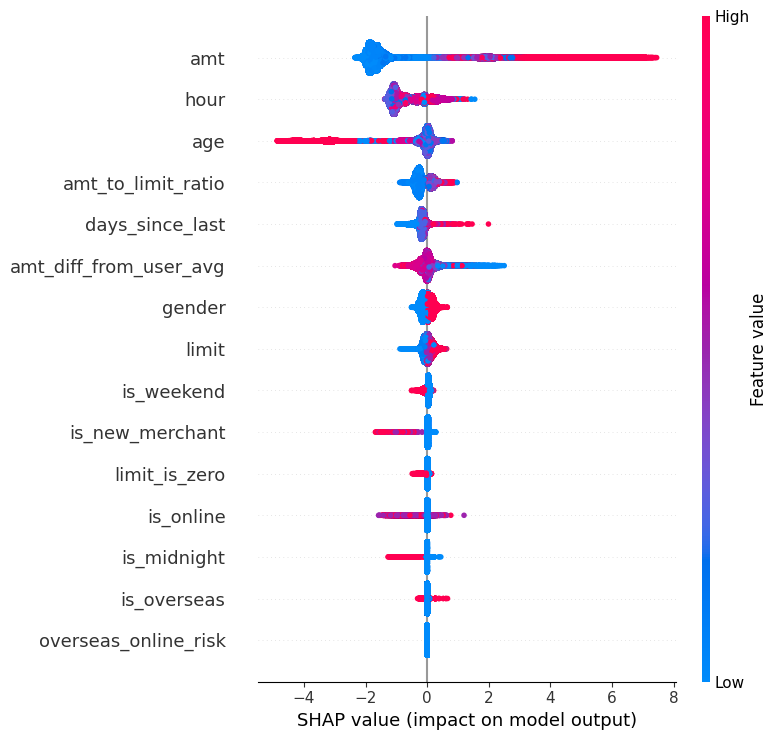

In [23]:
# 변수별 SHAP 영향 방향과 크기를 시각화합니다.
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    max_display=15,
)